# 04 — Load latency of every local memory level of the H100 NVL: shared memory, L1, L2 and HBM

**Goal.** How many SM cycles does one dependent load take when it is served by the SM's own shared memory, by its L1 cache, by the L2 cache or by HBM, using ordinary load instructions? The L2 of this GPU is split into two partitions, so "an L2 hit" and "an HBM access" are not single numbers: their latency depends on where the line lives relative to the requesting SM. The experiment therefore measures three things:

1. the classic latency-versus-working-set curve of a pointer chase, from 1 KiB to 2 GiB, for three cache operators and from SMs in both halves of the chip;
2. the latency of every individual access at 8 MiB (L2-resident) and 256 MiB (mostly HBM), sorted into latency classes;
3. how these classes depend on which SM touched the data first.

The resulting cycle counts are the reference latencies for all later measurements of distributed shared memory and of the asynchronous copy engine.

## Background

**Pointer chasing.** A buffer holds a chain of addresses: element *i* stores the address of element next(*i*). One thread executes `p = *p` repeatedly. Each load needs the result of the previous one, so loads cannot overlap. The time of *N* hops divided by *N* is the load-to-use latency of whatever level serves the data.
- Here every element sits in its own 128-byte line (the line size of L1 and L2), and next() is one random cycle through all lines of the working set. Hardware prefetchers cannot follow it, and every hop reads a different line.
- The working set (footprint) decides the level: a few KiB stay in L1, a few MiB in L2, and hundreds of MiB come from HBM.

**Timers.** `%clock64` counts cycles of the SM that executes the thread. A chase is timed with one read before and one after the loop; the second read is made to wait for the last load. Per-access timing places the two reads around every single load instead, which adds the cost of the timer pair (measured below) to each sample.

**Cache operators.** PTX `ld.global` takes a cache hint:
- `.ca` allows caching in L1 and L2;
- `.cg` caches only in L2 and bypasses L1;
- `.cv` means "volatile, fetch again".

They compile to SASS `LDG.E.64` with different memory-ordering qualifiers. Whether the data really bypasses a level is checked here with hardware counters.

**L1 and shared memory.** L1 and shared memory are one 256 KiB SRAM per SM. The driver splits it ("carveout") per kernel according to the kernel's shared-memory needs. The chase kernels here use no shared memory and request the largest L1. The resulting split is read back from the profiler.

**Shared memory through two paths.**
- `ld.shared` (SASS `LDS`) reads the SM's own shared memory directly.
- Inside a thread-block cluster, `mapa` converts a shared-memory address into the address of the same variable in any CTA of the cluster, and `ld.shared::cluster` reads it through the distributed-shared-memory (DSMEM) path. Pointed at the CTA's own rank, this measures the DSMEM path's fixed cost without any SM-to-SM transfer.

**L2 partitions, homing and replicas.**
- The L2 (60 MiB on this card) is built as two partitions, each attached to a subset of the GPCs.
- A line has a *home* in one partition. An SM reaching a line homed in the other partition pays an extra trip across the link between the partitions (the "far" case).
- The L2 may also keep copies of a line in the partition of the SM that uses it. The access types are then defined as:
  - a *near hit*: data found in the requesting SM's partition;
  - a *far hit*: data found only in the other partition;
  - *near* and *far misses*: the same split for data that comes from HBM, attached to either partition.

  Per-access latencies show which case each access was.
- **K-means classes.** The per-access cycle counts form tight groups. One-dimensional K-means finds their centres; the spread of each group is given as SD and as CV = SD / centre.

## Experimental setup

**Device and configuration.**
- NVIDIA H100 NVL: 132 SMs, 60 MiB L2, 94 GB HBM3 at 2619 MHz; power limit 400 W, ECC on, MIG off.
- Driver 580.126.20, CUDA 12.9 (`nvcc -arch=sm_90a -O3`).
- The SM clock is locked at 1635 MHz with `nvidia-smi -lgc`. Every recorded launch is followed by an NVML sample of the clocks and throttle reasons (table below).
- The L2 runs in its own clock domain at about 1556 MHz, so L2 and HBM latencies in SM cycles depend on this clock setting.

**Placement.** Every number comes from one thread on one known SM (`%smid`), with the rest of the GPU idle. The GPC of each SM comes from a separately determined map of this card (8 GPCs, G0–G7). Two placement methods:
- *Claim-based pinning* (chase kernels, toucher kernel). 264 one-warp blocks are launched without shared memory. The first block that finds itself on the target SM claims the work with an atomic and the others exit at once. This keeps the full L1 available. The host checks the claim and repeats the launch if no block ran on the target; the repeats are counted.
- *One CTA per SM* (per-access kernel). 132 blocks with 200 KB of shared memory each (the sample buffer), so every SM holds exactly one block.

**K1 — shared memory.** One block of 32 threads; thread 0 chases a chain of 32-bit shared-memory addresses with 16 loads unrolled per loop iteration.
- Strides: 1 word, 32 words (always the same bank), or a random cycle.
- Sizes: 1024, 8192 and 49 152 words.
- Hop counts 4096 and 16 384. The latency is the slope between the two, which removes the fixed cost of the timer reads and the loop exit.
- Load forms: `ld.shared`, `ld.volatile.shared`, and `mapa` to the own rank + `ld.shared::cluster` (launched as a cluster of one CTA).
- 2 warm-up and 10 recorded launches per configuration.

**K2 — footprint sweep.**
- One 2 GiB buffer; footprints from 1 KiB to 2 GiB in steps of ×1.25, plus exact points at 128 KiB, 25, 30, 50 and 60 MiB and 2 GiB.
- For each footprint the host writes the chain and copies it to the GPU.
- Each probe SM first chases the whole chain once untimed (inside the timed launch when the chain has ≤ 2²⁰ lines, so that L1 contents survive), then times max(lines, 2²⁰) hops: 5 recorded launches up to 2²⁰ lines (128 MiB), 3 above.
- With at least 2²⁰ hops per measurement, the fixed cost of the timed region (< 200 cycles) is below 0.0002 cycles per hop.
- Probe SMs: two in each half of the chip (the halves are found by K3, which runs first).

**K3 — every access.**
- Footprints 8 MiB (65 536 lines) and 256 MiB (2²¹ lines); the same chain buffers serve every configuration.
- One configuration:
  1. flush the L2 by streaming a 128 MB buffer;
  2. the *toucher* SM writes every line of the chain (whole lines, so that no partial line needs a fill from HBM);
  3. the *probe* SM chases 131 072 hops with `ld.global.cg` and times each one. At 8 MiB that is two full passes over all lines; at 256 MiB it is the first 6 % of the chain.
- Probes: the first SM of each of the 8 GPCs.
- *Matrix*: every toucher × probe combination (64 cells, 3 launches each), stored as exact histograms per cell and pass.
- *Raw samples*: for every probe, variant A (the probe touches the lines itself) and variant B (a toucher in another GPC, chosen from the matrix as the one that makes the probe's accesses slowest). Every sample is kept with its line address.
- A calibration chase of `ld.shared` with the same per-access timing measures the cost of the timer pair.

**Hardware counters.** Nsight Compute profiles one chase per cache operator at 64 KiB, 8 MiB and 256 MiB, right after a warm chase. Options:
- application replay, so that each counter pass sees the same warm caches;
- `--cache-control none`;
- `--clock-control none`, so that our clock lock stays in force.

In [1]:
%matplotlib inline
import re
import sys
sys.path.insert(0, "src")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from IPython.display import display, Markdown
from common04 import runs, latest_run, read_run, kmeans1d

R, EXP = "results", "04__memory_hierarchy_latency"
INK, INK2, GRID, SURF = "#0b0b0b", "#52514e", "#e4e3df", "#fcfcfb"
PAL = ["#2a78d6", "#eb6834", "#1baf7a", "#a35bd0", "#d4a20c", "#d6457a", "#4fb3c8", "#7a6e5c"]
plt.rcParams.update({
    "figure.facecolor": SURF, "axes.facecolor": SURF, "savefig.facecolor": SURF,
    "axes.edgecolor": INK2, "axes.labelcolor": INK, "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.spines.top": False,
    "axes.spines.right": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 110,
})
pd.set_option("display.precision", 2)

reg = runs()
RID = {m: latest_run(t, m) for t, m in [("lat_smem", "k1"), ("lat_fine", "calib"), ("lat_fine", "matrix"),
                                       ("lat_fine", "raw"), ("lat_footprint", "k2"), ("lat_footprint", "ncu")]}
k1 = read_run("04__latency__smem.csv", RID["k1"], dtype={"stride": str})
cal = read_run("04__latency__fine_calib.csv", RID["calib"])
hist = read_run("04__latency__fine_hist.csv", RID["matrix"])
fine = read_run("04__latency__fine.csv", RID["raw"])
k2 = read_run("04__latency__footprint.csv", RID["k2"])
ncu = read_run("04__latency__ncu_k2.csv", RID["ncu"])
clog = pd.read_csv(f"{R}/{EXP}__clock_log.csv")
clog = clog[clog.run_id.isin(RID.values())]
gmap = pd.read_csv("../03__sm_gpc_topology/results/03__sm_gpc_topology__map.csv")
GPC = gmap[gmap.run_id == gmap.run_id.max()].set_index("smid").gpc
MHZ = float(clog[clog.phase == "launch"].sm_clock_mhz.median())   # measured SM clock (NVML), for the ns axes
OUTLIER = 10000

In [2]:
first = clog.iloc[0]
L = clog[clog.phase == "launch"]
display(pd.DataFrame({
    "GPU": [first.gpu_name], "SMs": [first.sm_count], "CUDA runtime": [first.cuda_version], "driver": [first.driver_version],
    "locked SM clock (requested)": [f"{int(clog.lock_sm_mhz.max())} MHz"],
    "SM clock reported by NVML (min–max over all launches)": [f"{L.sm_clock_mhz.min()}–{L.sm_clock_mhz.max()} MHz"],
    "memory clock (NVML)": [f"{L.mem_clock_mhz.min()}–{L.mem_clock_mhz.max()} MHz"],
    "board power (min–max)": [f"{L.power_w.min():.0f}–{L.power_w.max():.0f} W"],
    "GPU / HBM temperature max": [f"{L.gpu_temp_c.max()} / {L.mem_temp_c.max()} °C"],
}).T.rename(columns={0: ""}))
used = reg[reg.run_id.isin(RID.values())].assign(mode=lambda r: r.cmdline.str.split().str[:2].str.join(" "))
used["recorded launches"] = used.run_id.map(L.groupby("run_id").size())
used["flagged launches (throttle or below lock)"] = used.run_id.map(L.groupby("run_id").apply(lambda g: int(((g.throttle == 1) | (g.below_lock == 1)).sum()), include_groups=False))
display(used[["run_id", "mode", "complete", "recorded launches", "flagged launches (throttle or below lock)"]].reset_index(drop=True))
nprof = reg[reg.cmdline.str.contains("lat_footprint ncu")].run_id
print(f"K2: {len(k2)} recorded launches, re-launches because no block reached the probe SM: {int(k2.groupby(['load_variant','footprint_bytes','smid']).retries.max().sum())}")
print(f"K2 under the profiler: {len(ncu)} profiled launches (application replay ran the binary {len(nprof)} times in total, including earlier smoke tests)")
print(f"K3: {len(fine):,} raw samples, {int(hist['count'].sum()):,} samples in the matrix histograms; "
      f"samples above {OUTLIER} cycles: raw {int((fine.cycles > OUTLIER).sum())}, matrix {int(hist.loc[hist.cycles > OUTLIER, 'count'].sum())} (excluded from K-means, kept in the data)")
print("Nothing was discarded.")

,
GPU,NVIDIA H100 NVL
SMs,132
CUDA runtime,12.9
driver,580.126.20
locked SM clock (requested),1635 MHz
SM clock reported by NVML (min–max over all launches),1635–1635 MHz
memory clock (NVML),2619–2619 MHz
board power (min–max),87–111 W
GPU / HBM temperature max,34 / 38 °C


,run_id,mode,complete,recorded launches,flagged launches (throttle or below lock)
0,2026-10-24T01:11:41.170+00:00,bin/lat_smem k1,True,540,0
1,2026-10-24T01:11:44.403+00:00,bin/lat_fine calib,True,24,0
2,2026-10-24T01:11:45.130+00:00,bin/lat_fine matrix,True,384,0
3,2026-10-24T01:12:25.349+00:00,bin/lat_fine raw,True,32,0
4,2026-10-24T01:12:33.113+00:00,bin/lat_footprint k2,True,3984,0
5,2026-10-24T01:52:58.503+00:00,/home/rid2/work/fa2026/iacoma/h100-microbench/...,True,9,0


K2: 3984 recorded launches, re-launches because no block reached the probe SM: 0
K2 under the profiler: 9 profiled launches (application replay ran the binary 10 times in total, including earlier smoke tests)
K3: 4,194,304 raw samples, 50,331,648 samples in the matrix histograms; samples above 10000 cycles: raw 0, matrix 5 (excluded from K-means, kept in the data)
Nothing was discarded.


## Results

### 1. Shared memory (K1)

Latency per hop from the slope between 4096 and 16 384 hops: median and p5–p95 over the 10 launches of each configuration. All launches ran on the SM listed.

In [3]:
t4 = k1[k1.hops == 4096].groupby(["variant", "stride", "n_words"]).total_cycles.median()
s = k1[k1.hops == 16384].copy()
s["slope"] = [(r.total_cycles - t4[(r.variant, r.stride, r.n_words)]) / 12288 for r in s.itertuples()]
tab = s.groupby(["variant", "stride", "n_words"]).agg(median=("slope", "median"), p5=("slope", lambda x: np.percentile(x, 5)),
                                                    p95=("slope", lambda x: np.percentile(x, 95)),
                                                    raw_ratio_16384=("cycles_per_hop", "median")).unstack("n_words")
display(tab.round(3))
LDS = float(s[s.variant == "lds"].slope.median()); DSM = float(s[s.variant == "dsmem_if"].slope.median())
print(f"SMs used: {sorted(k1.smid.unique())}; lds {LDS:.2f}, lds_volatile {s[s.variant=='lds_volatile'].slope.median():.2f}, "
      f"dsmem_if {DSM:.2f} cycles/hop ({DSM/MHZ*1e3:.1f} ns at {MHZ:.0f} MHz)")
sass = open("results/sass/lat_smem.sass").read().split("Function : ")
blk = [l for l in [b for b in sass if b.startswith("_Z8k1_chaseILi2E")][0].splitlines() if re.search(r"/\*[0-9a-f]{4}\*/", l)]
i = next(j for j, l in enumerate(blk) if "LD.E" in l)
print("\nSASS of the dsmem_if chain (ld.shared::cluster via mapa to the own rank):")
print("\n".join(l.split(";")[0].split("*/")[-1].strip() + ";" for l in blk[i - 3:i + 6]))

median                   p5                  p95         \
n_words              1024   8192   49152  1024   8192   49152  1024   8192    
variant      stride                                                           
dsmem_if     1       32.75  32.75  32.75  32.75  32.75  32.75  32.75  32.75   
             32      32.75  32.75  32.75  32.75  32.75  32.75  32.75  32.75   
             random  32.75  32.75  32.75  32.75  32.75  32.75  32.75  32.75   
lds          1       23.00  23.00  23.00  23.00  23.00  23.00  23.00  23.00   
             32      23.00  23.00  23.00  23.00  23.00  23.00  23.00  23.00   
             random  23.00  23.00  23.00  23.00  23.00  23.00  23.00  23.00   
lds_volatile 1       23.00  23.00  23.00  23.00  23.00  23.00  23.00  23.00   
             32      23.00  23.00  23.00  23.00  23.00  23.00  23.00  23.00   
             random  23.00  23.00  23.00  23.00  23.00  23.00  23.00  23.00   

                           raw_ratio_16384                
n_words              49152           1024   8192   49152  
variant      stride                                       
dsmem_if     1       32.75           32.75  32.75  32.75  
             32      32.75           32.75  32.75  32.75  
             random  32.75           32.75  32.75  32.75  
lds          1       23.00           23.00  23.00  23.00  
             32      23.00           23.00  23.00  23.00  
             random  23.00           23.00  23.00  23.00  
lds_volatile 1       23.00           23.00  23.00  23.00  
             32      23.00           23.00  23.00  23.00  
             random  23.00           23.00  23.00  23.00

SMs used: [np.int64(124)]; lds 23.00, lds_volatile 23.00, dsmem_if 32.75 cycles/hop (20.0 ns at 1635 MHz)

SASS of the dsmem_if chain (ld.shared::cluster via mapa to the own rank):
S2R R17, SR_SWINHI;
MOV R4, R10;
MOV R5, R17;
LD.E R4, [R4];
MOV R6, R4;
MOV R7, R17;
LD.E R6, [R6];
MOV R8, R6;
MOV R9, R17;


The stride does not matter for a single thread: bank conflicts arise only between threads of a warp that access the same bank in one instruction, and here only one thread issues loads. `ld.volatile.shared` compiles to the same `LDS` as `ld.shared`.

The DSMEM-path variant compiles to a generic `LD.E` whose 64-bit address is built from the 32-bit cluster address and the shared-window base (`SR_SWINHI`). This costs one dependent `MOV` per hop. Its cost is therefore the DSMEM path's fixed overhead plus that move, measured as the code a compiler emits for `ld.shared::cluster`.

### 2. Latency versus footprint (K2)

**Figure 1.** One panel per cache operator: the median over the recorded launches for each probe SM. The right axis converts to ns at the measured SM clock. The dotted lines mark:
- 128 KiB;
- the L1 capacity of this launch configuration (256 KiB minus the shared-memory carveout the driver chose, read back by the profiler);
- half of the L2 (30 MiB);
- the full L2 (60 MiB).

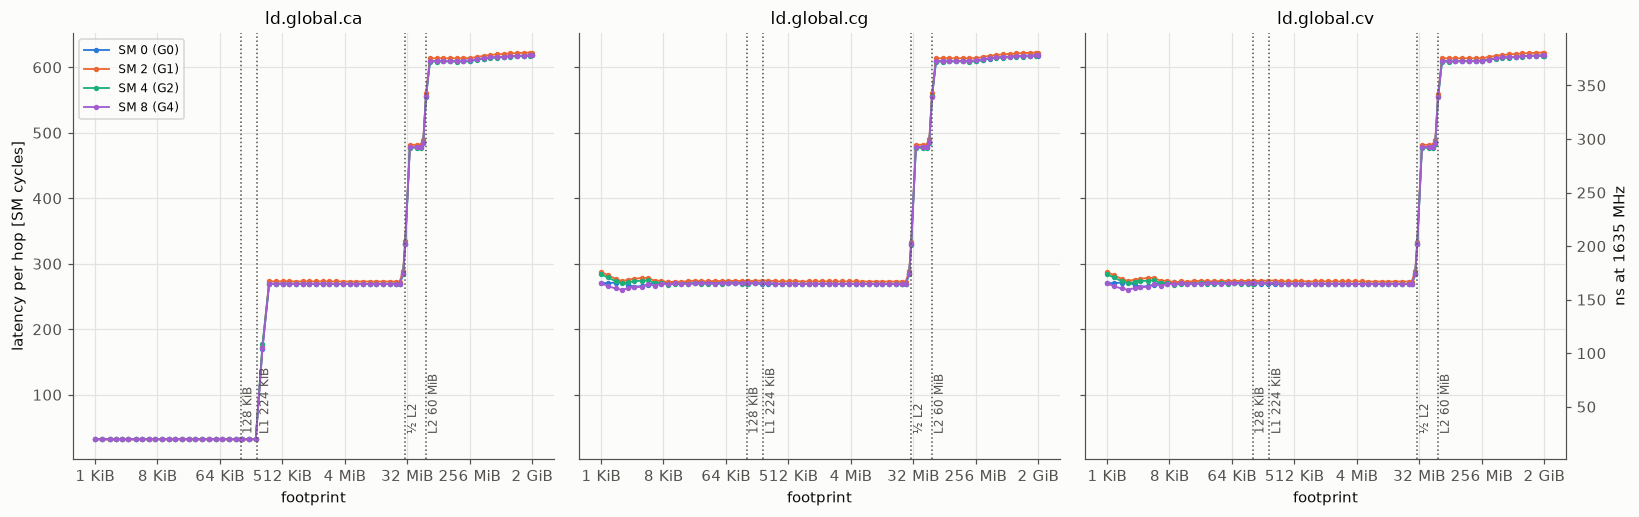

In [4]:
cfg_smem = int(ncu.launch__shared_mem_config_size.iloc[0])
L1CAP = 256 * 1024 - cfg_smem
SMS = sorted(k2.smid.unique(), key=lambda s: GPC[s])
med = k2.groupby(["load_variant", "smid", "footprint_bytes"]).cycles_per_hop.agg(["median", "min", "max"]).reset_index()
def kib(x, _=None):
    return f"{x/2**30:g} GiB" if x >= 2**30 else f"{x/2**20:g} MiB" if x >= 2**20 else f"{x/2**10:g} KiB"
fig, axs = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True)
for ax, v in zip(axs, ["ca", "cg", "cv"]):
    for c, sm in zip(PAL, SMS):
        d = med[(med.load_variant == v) & (med.smid == sm)]
        ax.plot(d.footprint_bytes, d["median"], "-o", ms=2.5, lw=1.2, color=c, label=f"SM {sm} (G{GPC[sm]})")
    for x, lab in [(128 * 1024, "128 KiB"), (L1CAP, f"L1 {L1CAP//1024} KiB"), (30 * 2**20, "½ L2"), (60 * 2**20, "L2 60 MiB")]:
        ax.axvline(x, ls=":", color=INK2, lw=1)
        ax.text(x * 1.05, 40, lab, rotation=90, fontsize=8, color=INK2, va="bottom")
    ax.set_xscale("log", base=2); ax.xaxis.set_major_formatter(FuncFormatter(kib))
    ax.set_xticks([2**k for k in range(10, 32, 3)])
    ax.set_title(f"ld.global.{v}"); ax.set_xlabel("footprint")
axs[0].set_ylabel("latency per hop [SM cycles]"); axs[0].legend(loc="upper left", fontsize=8)
sec = axs[2].secondary_yaxis("right", functions=(lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)); sec.set_ylabel(f"ns at {MHZ:.0f} MHz")
fig.tight_layout(); plt.show()

**Plateaus and transitions.** The plateau values are medians over all probe SMs and launches in the footprint ranges shown. A transition footprint is where the median curve (over the probe SMs) crosses halfway between two plateaus, interpolated on a log scale; the onset is where it first rises by 10 % of that step.

In [5]:
def curve(v):
    return k2[k2.load_variant == v].groupby("footprint_bytes").cycles_per_hop.median()
def plateau(v, lo, hi):
    d = k2[(k2.load_variant == v) & (k2.footprint_bytes >= lo) & (k2.footprint_bytes <= hi)].cycles_per_hop
    return (d.median(), np.percentile(d, 5), np.percentile(d, 95), len(d)) if len(d) else (np.nan,) * 3 + (0,)
def cross(c, level, after=0):
    c = c[c.index >= after]
    i = np.argmax(c.values >= level)
    if i == 0: return np.nan
    x0, x1, y0, y1 = np.log2(c.index[i - 1]), np.log2(c.index[i]), c.values[i - 1], c.values[i]
    return 2 ** (x0 + (level - y0) / (y1 - y0) * (x1 - x0))
PL = {
    "L1 (ca, ≤ 32 KiB)": plateau("ca", 0, 32 << 10),
    "L2 (cg, 1–16 MiB)": plateau("cg", 1 << 20, 16 << 20),
    "between ½ L2 and L2 (cg, 40–50 MiB)": plateau("cg", 40 << 20, 50 << 20),
    "HBM (cg, 256–512 MiB)": plateau("cg", 256 << 20, 512 << 20),
    "HBM (cg, 1.5–2 GiB)": plateau("cg", 3 << 29, 2 << 30),
}
display(pd.DataFrame(PL, index=["median", "p5", "p95", "launches"]).T.round(1))
l1, l2, hbm = PL["L1 (ca, ≤ 32 KiB)"][0], PL["L2 (cg, 1–16 MiB)"][0], PL["HBM (cg, 256–512 MiB)"][0]
ca, cg = curve("ca"), curve("cg")
rows = [("L1 → L2 (ca), onset", cross(ca, l1 + 0.1 * (l2 - l1))), ("L1 → L2 (ca), half step", cross(ca, (l1 + l2) / 2)),
        ("L2 → HBM (cg), onset", cross(cg, l2 + 0.1 * (hbm - l2), 1 << 20)), ("L2 → HBM (cg), half step", cross(cg, (l2 + hbm) / 2, 1 << 20))]
display(pd.DataFrame({"footprint": [kib(x) if x == x else "—" for _, x in rows]}, index=[r for r, _ in rows]))
pts = [16 << 10, 128 << 10, 192 << 10, 256 << 10, 1 << 20, 16 << 20, 25 << 20, 30 << 20, 40 << 20, 50 << 20, 60 << 20, 80 << 20,
       128 << 20, 256 << 20, 512 << 20, 1 << 30, 2 << 30]
near = lambda F: k2.footprint_bytes.unique()[np.argmin(np.abs(np.log(k2.footprint_bytes.unique() / F)))]
sel = k2[k2.footprint_bytes.isin([near(p) for p in pts])]
display(sel.pivot_table(index="footprint_bytes", columns=["load_variant", "smid"], values="cycles_per_hop", aggfunc="median")
        .rename(index=kib).round(1))

,median,p5,p95,launches
"L1 (ca, ≤ 32 KiB)",32.0,32.0,32.0,320.0
"L2 (cg, 1–16 MiB)",269.3,268.9,273.0,240.0
"between ½ L2 and L2 (cg, 40–50 MiB)",478.2,476.8,481.8,40.0
"HBM (cg, 256–512 MiB)",613.6,609.7,618.3,48.0
"HBM (cg, 1.5–2 GiB)",618.1,616.9,622.5,36.0


,footprint
"L1 → L2 (ca), onset",219.913 KiB
"L1 → L2 (ca), half step",255.835 KiB
"L2 → HBM (cg), onset",28.8123 MiB
"L2 → HBM (cg), half step",33.7036 MiB


load_variant        ca                          cg                       \
smid                 0      2      4      8      0      2      4      8   
footprint_bytes                                                           
14.5 KiB          32.0   32.0   32.0   32.0  271.3  272.5  268.8  269.3   
128 KiB           32.0   32.0   32.0   32.0  271.3  273.7  269.7  270.4   
211.75 KiB        32.0   32.0   32.0   32.0  269.2  274.3  270.1  270.8   
264.75 KiB       170.1  173.2  176.8  171.0  268.7  274.4  270.3  270.6   
1009.75 KiB      269.6  273.1  269.3  269.4  269.6  273.2  269.4  269.4   
14.3492 MiB      269.3  272.9  268.9  269.2  269.4  272.9  268.9  269.3   
25 MiB           269.2  272.9  269.1  269.2  269.3  272.9  269.0  269.2   
30 MiB           330.2  334.3  329.5  330.4  330.2  333.5  329.3  329.9   
43.7905 MiB      478.2  481.7  477.3  478.2  478.2  481.6  476.8  478.1   
50 MiB           478.2  481.7  477.3  478.5  478.4  481.7  477.1  478.1   
60 MiB           554.6  560.0  556.0  556.1  555.7  560.3  555.5  555.1   
85.5284 MiB      609.3  613.8  608.8  609.3  609.2  613.8  608.7  609.3   
133.638 MiB      609.4  613.7  608.9  609.3  609.3  613.8  608.9  609.4   
261.012 MiB      610.2  614.1  608.9  610.5  610.1  614.0  609.0  610.4   
509.789 MiB      615.2  618.9  614.6  615.1  615.2  618.8  614.6  615.1   
995.682 MiB      616.7  621.2  616.4  617.0  616.7  621.1  616.3  617.0   
2 GiB            618.2  622.3  618.0  618.3  617.9  622.2  618.4  618.3   

load_variant        cv                       
smid                 0      2      4      8  
footprint_bytes                              
14.5 KiB         271.2  272.5  268.7  269.3  
128 KiB          271.4  273.6  269.8  270.2  
211.75 KiB       269.3  274.2  270.3  270.7  
264.75 KiB       268.7  274.4  270.3  270.7  
1009.75 KiB      269.5  273.1  269.0  269.4  
14.3492 MiB      269.5  272.9  268.9  269.2  
25 MiB           269.3  272.9  269.0  269.3  
30 MiB           329.8  333.6  330.1  330.3  
43.7905 MiB      478.4  481.6  477.1  478.4  
50 MiB           478.6  481.8  477.0  478.7  
60 MiB           555.8  559.5  554.0  555.1  
85.5284 MiB      609.2  613.8  608.6  609.3  
133.638 MiB      609.5  613.8  608.9  609.3  
261.012 MiB      610.2  613.9  609.1  610.3  
509.789 MiB      615.3  618.8  614.5  615.1  
995.682 MiB      616.7  621.2  616.1  616.9  
2 GiB            617.9  622.4  617.8  618.3

**Which level served the chase.** Hardware counters of one profiled chase per configuration (after a warm chase; counts are for the whole kernel):
- L1 hit rate of global loads;
- L2 lookups requested by the SMs, as hits and misses per hop;
- sectors that crossed the link between the L2 partitions, per hop;
- HBM bytes read per hop.

In [6]:
n = ncu.copy()
hops = n.hops.astype(float)
tab = pd.DataFrame({
    "operator": "ld.global." + n.load_variant, "footprint": n.footprint_bytes.map(kib), "cycles/hop": n.cycles_per_hop_under_ncu,
    "L1 hit %": n["l1tex__t_sector_pipe_lsu_mem_global_op_ld_hit_rate.pct"],
    "L2 lookup hits / hop": n["lts__t_sectors_srcunit_tex_op_read_lookup_hit.sum"] / hops,
    "L2 lookup misses / hop": n["lts__t_sectors_srcunit_tex_op_read_lookup_miss.sum"] / hops,
    "partition-link sectors / hop": n["lts__t_sectors_srcunit_ltcfabric.sum"] / hops,
    "HBM bytes read / hop": n["dram__bytes_read.sum"] / hops,
    "counter passes": n.profiler__replayer_passes,
})
display(tab.round(3))
print(f"shared-memory carveout chosen by the driver: {cfg_smem // 1024} KiB → L1 {L1CAP // 1024} KiB; "
      f"SM clock during profiling {n['sm__cycles_elapsed.avg.per_second'].median()/1e6:.0f} MHz, L2 clock {n['lts__cycles_elapsed.avg.per_second'].median()/1e6:.0f} MHz")
ks = open("results/sass/lat_footprint.sass").read().split("Function : ")
for v, tag in [("ca", "ILi0E"), ("cg", "ILi1E"), ("cv", "ILi2E")]:
    b = [x for x in ks if x.startswith("_Z8k2_chase" + tag)][0]
    ld = next(l for l in b.splitlines() if "LDG" in l)
    print(f"ld.global.{v}: {ld.split(';')[0].split('*/')[-1].strip()}")

,operator,footprint,cycles/hop,L1 hit %,L2 lookup hits / hop,L2 lookup misses / hop,partition-link sectors / hop,HBM bytes read / hop,counter passes
0,ld.global.ca,64 KiB,32.12,99.95,0.0,0.0,1.00e-03,1.00e-03,4
1,ld.global.cg,64 KiB,272.68,0.00,1.0,0.0,0.00e+00,1.00e-03,4
2,ld.global.cv,64 KiB,272.63,0.00,1.0,0.0,0.00e+00,0.00e+00,4
3,ld.global.ca,8 MiB,272.01,0.00,1.0,0.0,0.00e+00,1.00e-03,4
4,ld.global.cg,8 MiB,272.01,0.00,1.0,0.0,0.00e+00,0.00e+00,4
5,ld.global.cv,8 MiB,272.04,0.00,1.0,0.0,0.00e+00,0.00e+00,4
6,ld.global.ca,256 MiB,612.73,0.00,0.0,2.0,1.04e+00,6.78e+01,4
7,ld.global.cg,256 MiB,612.74,0.00,0.0,2.0,1.04e+00,6.78e+01,4
8,ld.global.cv,256 MiB,612.74,0.00,0.0,2.0,1.04e+00,6.84e+01,4


shared-memory carveout chosen by the driver: 32 KiB → L1 224 KiB; SM clock during profiling 1632 MHz, L2 clock 1556 MHz
ld.global.ca: LDG.E.64.STRONG.SM R2, desc[UR6][R2.64]
ld.global.cg: LDG.E.64.STRONG.GPU R2, desc[UR6][R2.64]
ld.global.cv: LDG.E.64.STRONG.SYS R2, desc[UR6][R2.64]


### 3. Every access at 8 MiB and 256 MiB (K3)

**Figure 2.** Histograms of all per-access samples (raw run: variants A and B, all probes, all passes). Samples include the cost of the timer pair.

The dashed lines mark the K-means centres used in the analysis:
- **8 MiB: k = 2** (near and far L2 hits). The dotted lines show k = 4.
- **256 MiB: k = 6.** The histogram has five separated groups: near and far L2 hits, two HBM classes, and a broad slow tail that K-means splits in two. With k = 4 (dotted), the far L2 hits around 430 cycles merge into the faster HBM class.

The elbow table gives the within-class sum of squares for k = 1…6.

timer calibration: per-access-timed ld.shared 26.0 cycles vs chained latency 23.00 → timer pair adds 3.0 cycles to every K3 sample


,256 MiB,8 MiB
k,,
1,4.42e+10,6.12e+09
2,1.53e+10,3.72e+08
3,7.69e+09,1.37e+08
4,2.39e+09,9.57e+07
5,1.7e+09,5.67e+07
6,1.08e+09,4.15e+07


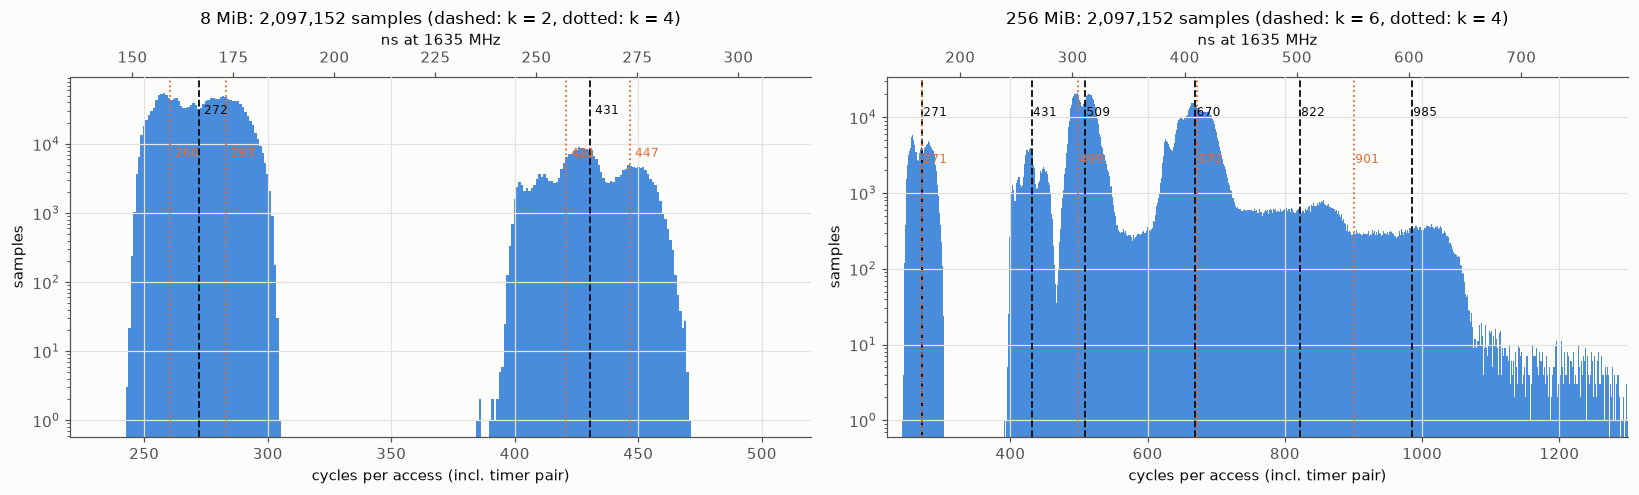

centre  centre − timer pair    SD  CV %  share %
footprint k class                                                  
8 MiB     2 0       272.2                269.2  13.0   4.8     87.5
            1       430.5                427.5  15.1   3.5     12.5
          4 0       260.5                257.5   6.1   2.3     42.1
            1       283.1                280.1   6.8   2.4     45.4
            2       420.8                417.8   9.1   2.2      7.8
            3       446.6                443.6   7.4   1.7      4.7
256 MiB   4 0       271.1                268.1  12.9   4.8      8.3
            1       499.0                496.0  30.2   6.1     44.7
            2       672.0                669.0  29.0   4.3     41.5
            3       900.6                897.6  82.2   9.1      5.5
          6 0       271.1                268.1  12.9   4.8      8.3
            1       431.0                428.0  15.1   3.5      5.6
            2       508.8                505.8  16.3   3.2     39.2
            3       669.5                666.5  24.4   3.6     40.4
            4       821.7                818.7  43.0   5.2      4.3
            5       985.1                982.1  53.3   5.4      2.3

In [7]:
calib = float(cal.cycles.median()); TPAIR = calib - LDS
print(f"timer calibration: per-access-timed ld.shared {calib:.1f} cycles vs chained latency {LDS:.2f} → timer pair adds {TPAIR:.1f} cycles to every K3 sample")
F8, F256 = 8 << 20, 256 << 20
fine["pass"] = np.where(fine.footprint_bytes == F8, fine.hop_idx // (F8 // 128), 0)
fine["var"] = np.where(fine.first_touch_smid == fine.probe_smid, "A", "B")
fk = fine[fine.cycles <= OUTLIER]
H = {F: fk[fk.footprint_bytes == F].cycles.value_counts().sort_index() for F in (F8, F256)}
KM, elbow = {}, {}
for F in (F8, F256):
    h = H[F]
    for k in range(1, 7):
        cen, lab, sd, wt = kmeans1d(h.index.values, h.values, k)
        KM[F, k] = (cen, lab, sd, wt)
        elbow[(kib(F), k)] = sum(((h.index.values[lab == j] - cen[j]) ** 2 * h.values[lab == j]).sum() for j in range(k))
display(pd.Series(elbow).unstack(0).map(lambda x: f"{x:.3g}").rename_axis("k"))
fig, axs = plt.subplots(1, 2, figsize=(15, 4.6))
for ax, F, ks_ in [(axs[0], F8, [(2, INK), (4, PAL[1])]), (axs[1], F256, [(6, INK), (4, PAL[1])])]:
    h = H[F]
    ax.bar(h.index, h.values, width=1.0, color=PAL[0], alpha=0.85)
    ax.set_yscale("log"); ax.set_xlim(220, 520 if F == F8 else 1300)
    for k, c in ks_:
        for j, x in enumerate(KM[F, k][0]):
            ax.axvline(x, color=c, ls="--" if k == ks_[0][0] else ":", lw=1.2)
            ax.text(x + 2, h.values.max() * (0.5 if k == ks_[0][0] else 0.12), f"{x:.0f}", color=c, fontsize=8)
    ax.set_title(f"{kib(F)}: {int(h.sum()):,} samples (dashed: k = {ks_[0][0]}, dotted: k = {ks_[1][0]})")
    ax.set_xlabel("cycles per access (incl. timer pair)"); ax.set_ylabel("samples")
    sec = ax.secondary_xaxis("top", functions=(lambda c: c / MHZ * 1e3, lambda n: n * MHZ / 1e3)); sec.set_xlabel(f"ns at {MHZ:.0f} MHz")
fig.tight_layout(); plt.show()
rows = []
for F, k in [(F8, 2), (F8, 4), (F256, 4), (F256, 6)]:
    cen, lab, sd, wt = KM[F, k]
    for j in range(k):
        rows.append({"footprint": kib(F), "k": k, "class": j, "centre": cen[j], "centre − timer pair": cen[j] - TPAIR,
                     "SD": sd[j], "CV %": 100 * sd[j] / cen[j], "share %": 100 * wt[j] / wt.sum()})
display(pd.DataFrame(rows).set_index(["footprint", "k", "class"]).round(1))

**Figure 3 — first touch.** For each probe SM, the share of far accesses (8 MiB, above the midpoint between the near and far centres):
- variant A: the probe touched the lines itself;
- variant B: a toucher in another GPC.

Each variant is split into the probe's first and second pass over the lines. The mean latency of each case is printed below the figure.

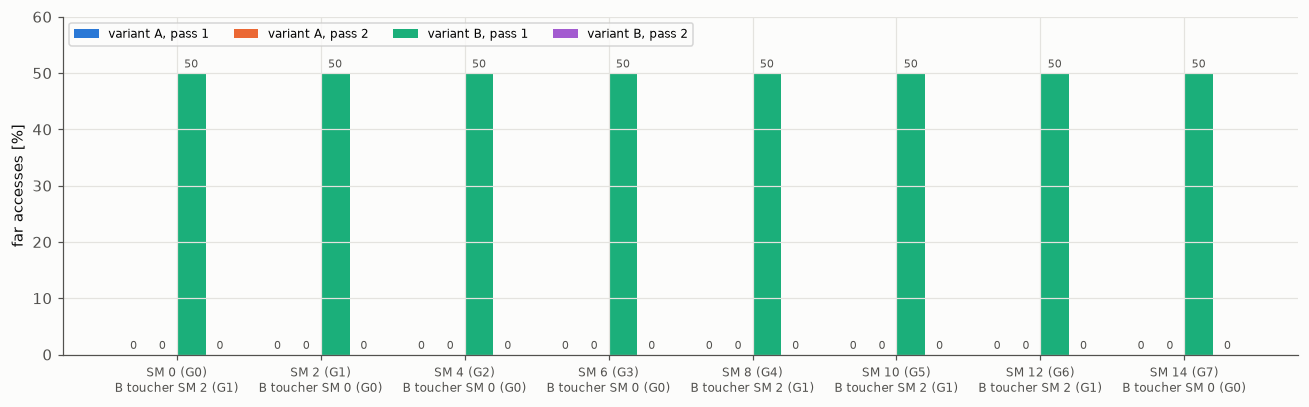

In [8]:
c8 = KM[F8, 2][0]; THR8 = (c8[0] + c8[1]) / 2
f8 = fk[fk.footprint_bytes == F8].assign(far=lambda d: d.cycles > THR8)
P = sorted(fine.probe_smid.unique(), key=lambda s: GPC[s])
tt = f8.groupby(["probe_smid", "var", "pass"]).agg(far=("far", "mean"), mean=("cycles", "mean")).reset_index()
fig, ax = plt.subplots(figsize=(12, 3.8))
w = 0.2
for i, (v, ps) in enumerate([("A", 0), ("A", 1), ("B", 0), ("B", 1)]):
    d = tt[(tt["var"] == v) & (tt["pass"] == ps)].set_index("probe_smid").loc[P]
    x = np.arange(len(P)) + (i - 1.5) * w
    ax.bar(x, 100 * d.far, w, color=PAL[i], label=f"variant {v}, pass {ps + 1}")
    for xi, y in zip(x, 100 * d.far.values):
        ax.text(xi, y + 1, f"{y:.0f}", ha="center", fontsize=7, color=INK2)
toucher = fine[fine["var"] == "B"].groupby("probe_smid").first_touch_smid.first()
ax.set_xticks(range(len(P)), [f"SM {p} (G{GPC[p]})\nB toucher SM {toucher[p]} (G{GPC[toucher[p]]})" for p in P], fontsize=8)
ax.set_ylabel("far accesses [%]"); ax.set_ylim(0, 60); ax.legend(fontsize=8, ncol=4, loc="upper left")
fig.tight_layout(); plt.show()
display(tt.pivot_table(index="probe_smid", columns=["var", "pass"], values="mean").loc[P].round(1)
        .rename(columns=lambda c: c, level=0).style.format("{:.1f}").set_caption("mean cycles per access (incl. timer pair)"))

**Figure 4 — who touched the line, for every pair of GPCs.** The share of far accesses in each toucher × probe cell of the matrix (8 MiB, the probe's first pass, 3 launches per cell), and at 256 MiB the share of HBM accesses (classes 2–3 of the 6-class solution) that fall into the slower HBM class. Rows and columns are ordered by the two groups that the matrix itself reveals.

groups of GPCs that see each other's lines as near: [['G0', 'G4', 'G5', 'G6'], ['G1', 'G2', 'G3', 'G7']]


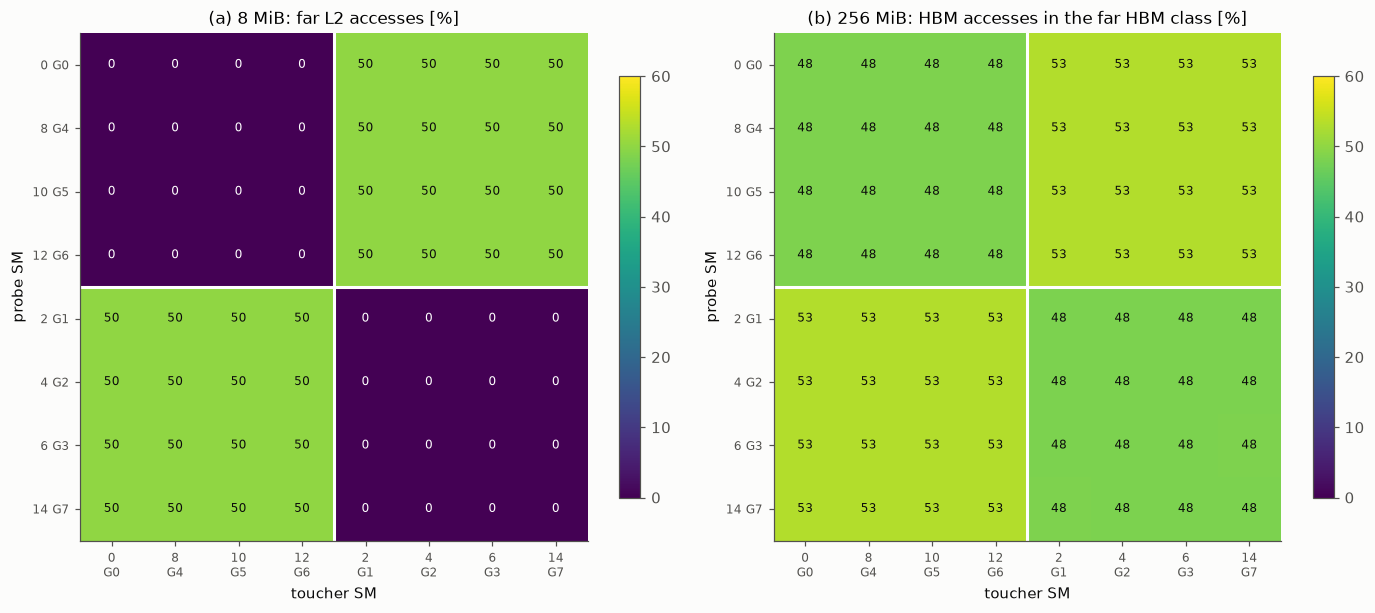

In [9]:
m8 = hist[(hist.footprint_bytes == F8) & (hist["pass"] == 0) & (hist.cycles <= OUTLIER)]
far8 = (m8.assign(f=m8["count"] * (m8.cycles > THR8)).groupby(["probe_smid", "first_touch_smid"])
        .apply(lambda g: g.f.sum() / g["count"].sum(), include_groups=False).unstack())
groups = sorted({tuple(sorted((int(t) for t in far8.columns if far8.loc[p, t] < 0.1), key=lambda s: GPC[s])) for p in far8.index},
                key=lambda g: GPC[g[0]])
order = [s for g in groups for s in g]
print("groups of GPCs that see each other's lines as near:", [[f"G{GPC[s]}" for s in g] for g in groups])
c256 = KM[F256, 6][0]; B12 = (c256[1] + c256[2]) / 2; TD = (c256[2] + c256[3]) / 2; TS = (c256[3] + c256[4]) / 2
m256 = hist[(hist.footprint_bytes == F256) & (hist.cycles <= OUTLIER)]
far256 = (m256.assign(f=m256["count"] * ((m256.cycles > TD) & (m256.cycles <= TS)), d=m256["count"] * ((m256.cycles > B12) & (m256.cycles <= TS)))
          .groupby(["probe_smid", "first_touch_smid"]).apply(lambda g: g.f.sum() / g.d.sum(), include_groups=False).unstack())
fig, axs = plt.subplots(1, 2, figsize=(13, 5.4))
for ax, M, title, vmax in [(axs[0], far8, "(a) 8 MiB: far L2 accesses [%]", 60), (axs[1], far256, "(b) 256 MiB: HBM accesses in the far HBM class [%]", 60)]:
    A = 100 * M.loc[order, order].values
    im = ax.imshow(A, cmap="viridis", vmin=0, vmax=vmax)
    for i in range(len(order)):
        for j in range(len(order)):
            ax.text(j, i, f"{A[i, j]:.0f}" if vmax > 1 else "", ha="center", va="center", fontsize=8, color="white" if A[i, j] < 35 else INK)
    lab = [f"{s}\nG{GPC[s]}" for s in order]
    ax.set_xticks(range(len(order)), lab, fontsize=8); ax.set_yticks(range(len(order)), [l.replace("\n", " ") for l in lab], fontsize=8)
    ax.set_xlabel("toucher SM"); ax.set_ylabel("probe SM"); ax.set_title(title); ax.grid(False)
    ax.axhline(len(groups[0]) - 0.5, color="white", lw=2); ax.axvline(len(groups[0]) - 0.5, color="white", lw=2)
    fig.colorbar(im, ax=ax, shrink=0.8)
fig.tight_layout(); plt.show()

**Figure 5 — the same lines seen from different SMs.** All probes of the raw run chase the same buffer in the same order, so each line's latency class can be compared between probes. Each cell is the share of lines on which two probes agree:
- (a) near or far at 8 MiB, variant B, first pass;
- (b) which of the two near sub-classes (Figure 2, k = 4) at 8 MiB, variant A, second pass;
- (c) which of the two main HBM classes (6-class solution, classes 2 and 3) at 256 MiB, variant A, for lines that both probes read from HBM.

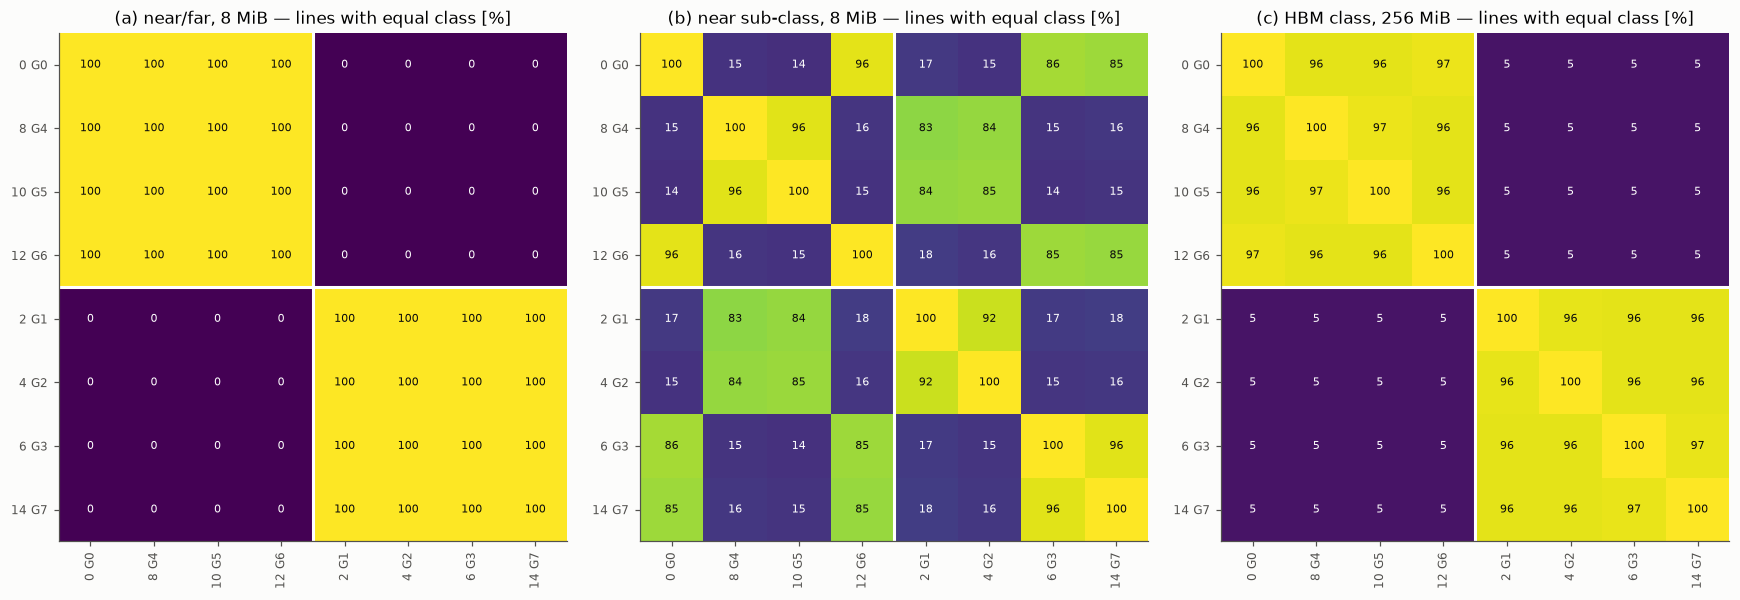

lines per comparison: (a) 65,536, (b) 65,536–65,536 near samples per probe, (c) 103,692–104,120 HBM samples per probe
closest partner in near sub-class labels: [('G0', 'G6', 96), ('G1', 'G2', 92), ('G3', 'G7', 96), ('G4', 'G5', 96)]


In [10]:
def agreement(lbl):
    cols = list(order)
    out = np.full((len(cols), len(cols)), np.nan)
    for i, p in enumerate(cols):
        for j, q in enumerate(cols):
            ok = lbl[p].notna() & lbl[q].notna()
            out[i, j] = (lbl.loc[ok, p] == lbl.loc[ok, q]).mean()
    return out
la = f8[(f8["var"] == "B") & (f8["pass"] == 0)].pivot(index="line_offset", columns="probe_smid", values="far")
c84 = KM[F8, 4][0]; SUB = (c84[0] + c84[1]) / 2
nb = f8[(f8["var"] == "A") & (f8["pass"] == 1) & (~f8.far)]
lb = nb.assign(s=nb.cycles > SUB).pivot(index="line_offset", columns="probe_smid", values="s")
d256 = fk[(fk.footprint_bytes == F256) & (fk["var"] == "A")]
d256 = d256[(d256.cycles > B12) & (d256.cycles <= TS)]
lc = d256.assign(s=d256.cycles > TD).pivot(index="line_offset", columns="probe_smid", values="s")
fig, axs = plt.subplots(1, 3, figsize=(16, 5.2))
AG = {}
for ax, (key, lbl, title) in zip(axs, [("a", la, "(a) near/far, 8 MiB"), ("b", lb, "(b) near sub-class, 8 MiB"), ("c", lc, "(c) HBM class, 256 MiB")]):
    A = agreement(lbl.astype(object).where(lbl.notna())); AG[key] = A
    im = ax.imshow(100 * A, cmap="viridis", vmin=0, vmax=100)
    for i in range(len(order)):
        for j in range(len(order)):
            ax.text(j, i, f"{100*A[i, j]:.0f}", ha="center", va="center", fontsize=7.5, color="white" if A[i, j] < 0.6 else INK)
    lab = [f"{s} G{GPC[s]}" for s in order]
    ax.set_xticks(range(len(order)), lab, rotation=90, fontsize=8); ax.set_yticks(range(len(order)), lab, fontsize=8)
    ax.set_title(title + " — lines with equal class [%]"); ax.grid(False)
    ax.axhline(len(groups[0]) - 0.5, color="white", lw=2); ax.axvline(len(groups[0]) - 0.5, color="white", lw=2)
fig.tight_layout(); plt.show()
print(f"lines per comparison: (a) {la.shape[0]:,}, (b) {lb.notna().sum().min():,}–{lb.notna().sum().max():,} near samples per probe, "
      f"(c) {lc.notna().sum().min():,}–{lc.notna().sum().max():,} HBM samples per probe")
sub = pd.DataFrame(AG["b"], index=order, columns=order)
pairs = sorted({tuple(sorted((p, int(sub.loc[p].drop(p).idxmax())), key=lambda s: GPC[s])) for p in order}, key=lambda t: GPC[t[0]])
print("closest partner in near sub-class labels:", [(f"G{GPC[a]}", f"G{GPC[b]}", round(100 * sub.loc[a, b])) for a, b in pairs])

In [11]:
# Slow HBM class at 256 MiB: is it a property of the line, of the SM, or of both?
slow = fk[(fk.footprint_bytes == F256) & (fk["var"] == "A")].assign(s=lambda d: d.cycles > TS).pivot(index="line_offset", columns="probe_smid", values="s")
base = slow.mean()
cond = pd.DataFrame({p: {q: (slow[p] & slow[q]).sum() / slow[p].sum() for q in order} for p in order}).T.loc[order, order]
s256 = fk[(fk.footprint_bytes == F256) & (fk["var"] == "A")]
dec = (s256.cycles > TS).groupby(s256.hop_idx * 10 // s256.hop_idx.max().clip(1)).mean().clip(upper=1)
print(f"slow-class share per probe: {100*base.min():.1f}–{100*base.max():.1f} %; per tenth of the chase (hop order): "
      + ", ".join(f"{100*x:.1f}" for x in dec.values[:10]) + " %")
display((100 * cond).round(0).rename(index=lambda s: f"{s} G{GPC[s]}", columns=lambda s: f"{s} G{GPC[s]}")
        .style.format("{:.0f}").set_caption("P(slow on column probe | slow on row probe) [%], 256 MiB, variant A"))

slow-class share per probe: 6.3–6.6 %; per tenth of the chase (hop order): 6.2, 6.3, 6.5, 6.4, 6.4, 6.5, 6.6, 6.4, 6.5, 6.6 %


,0 G0,8 G4,10 G5,12 G6,2 G1,4 G2,6 G3,14 G7
0 G0,100,28,30,46,8,8,8,8
8 G4,28,100,45,29,8,8,9,8
10 G5,30,45,100,27,9,8,8,8
12 G6,47,29,27,100,8,8,8,8
2 G1,8,8,8,8,100,34,28,27
4 G2,8,8,8,8,35,100,30,31
6 G3,8,8,8,8,29,31,100,47
14 G7,8,8,8,8,27,31,46,100


### 4. Summary

One latency per level (`results/04__latency__summary.csv`, also used as the reference lines of later experiments). The values come from:
- SMEM and DSMEM-path: K1 slopes.
- L1: K2 `ld.global.ca` at ≤ 32 KiB.
- L2 near/far: K-means classes of every 8 MiB access (k = 2).
- HBM near/far/slow: classes 2, 3 and 4 + 5 of every 256 MiB access (k = 6; classes 0 and 1 are near and far L2 hits).
- Plain-chase L2 and HBM: K2 `ld.global.cg` plateaus.

Per-access values have the timer-pair cost subtracted.

In [12]:
summ = pd.read_csv(f"{R}/04__latency__summary.csv")
summ = summ[summ.run_id == summ.run_id.max()]
summ = summ.assign(ns=summ.median_cycles / MHZ * 1e3)[["level", "median_cycles", "p5", "p95", "ns", "n", "timer_correction_cycles", "source"]]
display(summ.set_index("level").round(1))

,median_cycles,p5,p95,ns,n,timer_correction_cycles,source
level,,,,,,,
smem,23.0,23.0,23.0,14.1,90,0.0,K1 lds slope
smem_dsmem_if,32.8,32.8,32.8,20.0,90,0.0,K1 dsmem_if slope
l1,32.0,32.0,32.0,19.6,320,0.0,K2 ca <= 32 KiB
l2_near,270.0,249.0,290.0,165.1,1835008,3.0,K3 8 MiB 2-means class 0 (centre 269.2; 0 samp...
l2_far,426.0,402.0,452.0,260.6,262144,3.0,K3 8 MiB 2-means class 1 (centre 427.5; 0 samp...
dram_near,505.0,483.0,532.0,308.9,822369,3.0,K3 256 MiB 6-means class 2 (centre 505.8; 0 sa...
dram_far,667.0,624.0,705.0,408.0,846396,3.0,K3 256 MiB 6-means class 3 (centre 666.5; 0 sa...
dram_slow,856.0,754.0,1030.0,523.5,138281,3.0,"K3 256 MiB 6-means class 4+5 (centre 818.7, 98..."
l2_chase,269.3,268.9,273.0,164.7,240,0.0,K2 cg 1-16 MiB


## Insights

### The latency ladder
SM cycles at the locked 1635 MHz, with ns in parentheses. Per-access values have the 3-cycle timer pair removed.

| access | latency |
|---|---|
| shared memory, `ld.shared` | **23** (14 ns) |
| own shared memory through the DSMEM path | **32.75** (20 ns) |
| L1 hit | **32** (20 ns) |
| L2 hit, near | **270** (165 ns) |
| L2 hit, far | **426** (261 ns) |
| HBM, near | **505** (309 ns) |
| HBM, far | **667** (408 ns) |

A plain pointer chase reports 269 cycles for an L2-resident footprint and 614–618 cycles for footprints far beyond the L2. Every class is tight: CV ≤ 6 % for the hit and miss classes.

### L1, cache operators and the DSMEM path
- **L1 holds 224 KiB with this kernel configuration.**
  - The driver chose a 32 KiB shared-memory carveout for kernels without shared memory, which leaves 224 KiB of the 256 KiB SRAM as L1.
  - `ld.global.ca` stays at 32 cycles up to 212 KiB and reaches the L2 latency by 1 MiB.
  - An L1 hit costs 9 cycles more than a shared-memory load from the same SRAM.
- **`.cg` and `.cv` behave identically.**
  - Both skip L1, and both are served by L2 (exactly one L2 hit per load in the counters).
  - `.cv` (SASS `LDG.E.64.STRONG.SYS`) does not bypass the L2 for device memory.
  - `.ca` compiles to `LDG.E.64.STRONG.SM` and caches in L1 as intended.
- **The DSMEM path costs 9.75 cycles more than `LDS`, even for the CTA's own memory.** That cost includes the one register move per hop that the compiler needs to form the 64-bit cluster-window address. It is a floor under every remote shared-memory access, before any SM-to-SM transfer.

### The L2 is two partitions of four GPCs each
- **The groups are {G0, G4, G5, G6} and {G1, G2, G3, G7}.**
  - When a line was first touched in the other group, every probe sees exactly half the lines of a random buffer as far.
  - The far lines are identical for all GPCs of a group and complementary between the groups (Figure 5a).
  - Hence each line has an address-determined home partition, and a far hit costs **+156 cycles (+95 ns)** over a near hit.
- **Copies follow the user.** Writing or reading a line leaves a copy in the accessing SM's partition:
  - lines touched within the probe's own group are 100 % near;
  - lines touched by the other group are 50 % far on the first read and 100 % near on the second read (Figures 3 and 4).

  The first access pays the far latency, every later access from that partition is near.
- **Consequences for pointer-chase curves.**
  - An L2-resident chase never sees a far hit: the partition link carries no traffic at 8 MiB, and the L2 plateau is the near-hit latency for SMs of both partitions.
  - The near/far split is therefore invisible in latency-versus-footprint curves. They are the same for every probe SM within 4 cycles: the G1 SM is 3–4 cycles slower than the others at every footprint beyond L1.
  - Measuring a far hit requires controlling who touched the line, as in K3.
- **A single SM's working set fits only half the L2.** The near-hit plateau ends at about 29 MiB (onset) and reaches half the step to HBM at 34 MiB. This matches every line being kept in the reader's own partition, which is half of the 60 MiB.
  - Between 40 and 50 MiB the chase sits on an intermediate plateau of 478 cycles.
  - At 60 MiB it reaches 555 cycles, and from about 85 MiB the full HBM latency.

### Sub-nodes inside each partition
- **Near hits come in two classes about 23 cycles apart (≈ 258 and ≈ 280 cycles).** Far hits split the same way (≈ 418 and ≈ 444).
- **Which class a line falls into is shared by pairs of GPCs:** {G0, G6} and {G4, G5} in one partition, {G1, G2} and {G3, G7} in the other (92–96 % agreement per line, Figure 5b).
- So each partition consists of two sub-nodes of two GPCs, and reaching data in the other sub-node of the same partition costs about 23 cycles.
- The assignment of lines to sub-nodes corresponds between the partitions: {G0, G6} agrees with {G3, G7} on 85 % of lines, and {G4, G5} with {G1, G2} on 84 %.

### HBM
- **The partition split carries over to misses.**
  - The two main HBM classes (505 and 667 cycles, **+162**) follow the same per-line partition groups (96–97 % agreement within a group, 5 % across, Figure 5c).
  - A small first-touch effect remains: 48 % vs 53 % of misses fall into the slower class depending on the toucher's partition (Figure 4b).
- **Each class has sub-peaks:** 496/515 and 628/667 cycles in the histogram (including the timer pair).
- **About 6.5 % of HBM accesses form a broad slow tail** between about 750 and 1050 cycles.
  - It is spread evenly over the duration of the chase.
  - It is partly a property of the line together with the requesting sub-node. A line that is slow for one SM is also slow for its sub-node partner 34–47 % of the time, for the other sub-node of the same partition 27–31 %, and in the other partition 8 %, close to the 6.5 % base rate.
  - DRAM bank or row conflicts would fit this pattern, but these measurements do not identify the cause.
- **Each HBM access caused two L2 lookups and about one sector of traffic on the partition link** (counters at 256 MiB).
- **Address translation adds little:** the chase latency grows by only 9 cycles from 128 MiB to 2 GiB.

### Limitations and anomalies
- **Clock dependence.** L2 and HBM latencies in SM cycles depend on the clock setting: the L2 runs at 1556 MHz against the 1635 MHz SM clock. The ns values are the clock-independent form.
- **Sample size for the partition and sub-node structure.** It is inferred from one SM per GPC and one buffer per footprint. SMs within one GPC were not compared with each other.
- **Excluded samples.** Five isolated samples of ≈ 0.5 ms each (1 in 10 million) were excluded from the K-means fits and remain in the data.
- **Clocks.** No launch showed a throttle reason or a clock below the lock, and no launch was discarded.